# Posição da capital nos perfis

A capital ficou fora da modelagem por não ter IEGM: ela é fiscalizada pelo
Tribunal de Contas do Município de São Paulo, e não pelo TCE-SP. Este
notebook identifica de qual dos quatro perfis a capital mais se aproxima,
usando apenas os blocos de criminalidade e socioeconômico (15 das 22
features), e mede o quanto essa aproximação é confiável.

Saídas:

- `data/processed/tabela_capital.csv`: a distância da capital ao centro de
  cada perfil, o perfil mais próximo e a taxa de acerto do método nos 644
  municípios;
- `data/processed/tabela_capital_variaveis.csv`: a capital e a média de cada
  perfil em cada uma das 15 variáveis, com a marcação das variáveis em que a
  capital fica fora da faixa dos 644;
- figura de apoio: `figura_mapa_perfis_com_capital` (a Figura 6 não muda).

### Critérios definidos antes da execução

- A capital é levada à **escala dos 644**: `log1p` nas mesmas colunas e
  padronização com a média e o desvio dos 644, sem refazer a padronização
  com a capital dentro. Os pesos por bloco são os da matriz original.
- O perfil apontado é o de **centro mais próximo** nas 15 colunas.
- **Teste de confiança do método**: a mesma regra, aplicada aos 644
  municípios sem o bloco de gestão, deve devolver o perfil original da
  maioria deles. Uma taxa de acerto baixa indica que o resultado da capital
  vale pouco.
- Toda variável em que a capital fica fora da faixa observada nos 644 é
  sinalizada como **extrapolação**.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# Os notebooks ficam em notebooks/ e o código do projeto em src/. Estas duas
# linhas apontam o Python para src/, para os "from config import ..." abaixo
# funcionarem tanto rodando daqui quanto da raiz do projeto.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

from config import (ALGORITMO_ESCOLHIDO, BASE_FINAL_CSV, CODIGO_CAPITAL,
                    DATA_PROCESSED, DICIONARIO_CSV, K_ESCOLHIDO)
from estilo import aplicar_estilo, salvar
from figuras import plot_mapa_com_destaque
from malha import carregar_malha_sp
from preprocessamento import (carregar_features, escala_de_referencia,
                              montar_matriz, transformar_com_escala)
from clusterizacao import distancias_aos_centros

aplicar_estilo()   # mesma fonte, cores e grade em todas as figuras do artigo
# Se algum import acima falhar, quase sempre é o editor apontando para outra
# instalação do Python. O caminho impresso aqui é o que precisa ter as
# bibliotecas do requirements.txt.
print("Python:", sys.executable)
print(f"Modelo escolhido: {ALGORITMO_ESCOLHIDO}, k = {K_ESCOLHIDO}")

# O código do IBGE é identificador, não quantidade: lido como texto para não
# virar número em nenhuma etapa.
base = pd.read_csv(BASE_FINAL_CSV, dtype={"codigo_ibge": str})
dic = pd.read_csv(DICIONARIO_CSV)
perfis = pd.read_csv(DATA_PROCESSED / "perfis.csv", dtype={"codigo_ibge": str})

Python: D:\RP 2\database-rp2\.venv\Scripts\python.exe
Modelo escolhido: kmeans, k = 4


## 1. A capital na escala dos 644

A média e o desvio de cada feature são calculados nos 644 municípios, depois
do `log1p`, e aplicados à capital. O `assert` confere que essa escala é a
mesma usada pela `montar_matriz` na matriz original: aplicada aos 644, ela
tem que reproduzir exatamente a matriz padronizada `Z`.

In [2]:
features, bloco_de = carregar_features(dic)
# Mesmo filtro e mesma ordem do notebook 05 (sem a capital, que não tem IEGM).
modelagem = base[~base["flag_sem_iegm"]].reset_index(drop=True)
assert (modelagem["codigo_ibge"] == perfis["codigo_ibge"]).all(), \
    "perfis.csv fora da ordem da base"
perfil = perfis["perfil"].to_numpy()
capital = base[base["codigo_ibge"] == CODIGO_CAPITAL]
assert len(capital) == 1 and capital["flag_sem_iegm"].all()

Z, W, peso = montar_matriz(modelagem, features, bloco_de)
media, desvio = escala_de_referencia(modelagem, features, bloco_de)
assert np.allclose(transformar_com_escala(modelagem, features, bloco_de,
                                          media, desvio), Z), \
    "a escala não é a mesma da montar_matriz"

# As 15 features sem o bloco de gestão, que a capital não tem.
f15 = [c for c in features if bloco_de[c] != "gestao"]
z_capital = transformar_com_escala(capital, f15, bloco_de, media, desvio).iloc[0]
assert z_capital.notna().all(), "a capital tem valor ausente em alguma feature"
print(f"{len(f15)} features; pesos: "
      + ", ".join(f"{b} {peso[[c for c in f15 if bloco_de[c] == b][0]]:.3f}"
                  for b in ["criminalidade", "socioeconomico"]))

15 features; pesos: criminalidade 0.333, socioeconomico 0.408


## 2. Distância da capital aos perfis

O centro de cada perfil é a média dos seus municípios nas 15 colunas da
matriz ponderada (os mesmos pesos `1/√n` da matriz original). A distância é
a mesma distância em linha reta usada pelo K-means.

In [3]:
W15 = Z[f15] * peso[f15]
w_capital = (z_capital * peso[f15]).to_frame().T
dist_capital = distancias_aos_centros(W15, perfil, w_capital).iloc[0]
ordem = dist_capital.sort_values()
mais_proximo, segundo = ordem.index[0], ordem.index[1]
print(f"perfil mais próximo: {mais_proximo} (distância {ordem.iloc[0]:.3f}); "
      f"segundo: {segundo} ({ordem.iloc[1]:.3f})")
dist_capital.rename("distancia").round(3).to_frame()

perfil mais próximo: 4 (distância 1.304); segundo: 3 (1.590)


,distancia
1,3.030
2,2.453
3,1.590
4,1.304


## 3. Teste de confiança do método

A mesma regra é aplicada a cada um dos 644 municípios: o perfil apontado é o
de centro mais próximo nas 15 colunas, sem o bloco de gestão. A taxa de
acerto é a proporção de municípios em que a regra devolve o perfil original.
Como os centros são calculados com os próprios 644, o teste é favorável ao
método; ainda assim, mostra o quanto o bloco de gestão pesa na separação dos
perfis.

In [4]:
dist_644 = distancias_aos_centros(W15, perfil, W15)
# idxmin(axis=1) devolve, em cada linha, o nome da coluna com a menor
# distância, isto é, o perfil mais próximo.
apontado = dist_644.idxmin(axis=1).to_numpy()
acerto = (apontado == perfil).mean()
print(f"taxa de acerto nos 644: {acerto:.3f} ({(apontado == perfil).sum()} de {len(perfil)})")
# Acerto dentro de cada perfil original.
acerto_por_perfil = pd.Series(apontado == perfil).groupby(perfil).mean()
print("acerto por perfil:", acerto_por_perfil.round(3).to_dict())
# Para comparar com a capital: quão longe os 644 costumam ficar do centro
# mais próximo, e quantos ficam mais longe do que a capital fica.
dist_min_644 = dist_644.min(axis=1)
mais_longe = (dist_min_644 > ordem.iloc[0]).mean()
print(f"distância mediana dos 644 ao centro mais próximo: {dist_min_644.median():.3f}; "
      f"{mais_longe:.1%} deles ficam mais longe do que a capital ({ordem.iloc[0]:.3f})")
pd.crosstab(pd.Series(perfil, name="perfil original"),
            pd.Series(apontado, name="perfil apontado (15 colunas)"),
            margins=True, margins_name="total")

taxa de acerto nos 644: 0.781 (503 de 644)
acerto por perfil: {1: 0.97, 2: 0.899, 3: 0.648, 4: 0.709}
distância mediana dos 644 ao centro mais próximo: 0.986; 23.4% deles ficam mais longe do que a capital (1.304)


perfil apontado (15 colunas),1,2,3,4,total
perfil original,,,,,
1,64,2,0,0,66
2,1,195,17,4,217
3,0,13,127,56,196
4,0,11,37,117,165
total,65,221,181,177,644


## 4. A capital em cada variável

A tabela mostra, para cada uma das 15 variáveis, o valor da capital em
desvios em relação à média dos 644 (na escala da matriz, isto é, depois do
`log1p` nas taxas e nas variáveis em reais) ao lado da média de cada perfil
na mesma escala, como na Figura 5. As colunas `min_644` e `max_644` trazem a
faixa dos 644 em unidades originais, e `fora_da_faixa` marca as variáveis em
que a capital fica abaixo do mínimo ou acima do máximo.

In [5]:
variaveis = pd.DataFrame({
    "capital_valor": capital[f15].iloc[0],
    "min_644": modelagem[f15].min(),
    "max_644": modelagem[f15].max(),
    "capital_desvios": z_capital,
})
# Médias de cada perfil em desvios, como na Figura 5 (Z, sem o peso).
medias_perfis = Z[f15].groupby(perfil).mean().T
medias_perfis.columns = [f"perfil_{p}" for p in medias_perfis.columns]
variaveis = variaveis.join(medias_perfis)
variaveis["fora_da_faixa"] = ((variaveis["capital_valor"] > variaveis["max_644"])
                              | (variaveis["capital_valor"] < variaveis["min_644"]))
variaveis.index.name = "variavel"
variaveis.to_csv(DATA_PROCESSED / "tabela_capital_variaveis.csv")
print("fora da faixa dos 644:", list(variaveis.index[variaveis["fora_da_faixa"]]))
variaveis.round(2)

fora da faixa dos 644: ['taxa_roubo_outros']


,capital_valor,min_644,max_644,capital_desvios,perfil_1,perfil_2,perfil_3,perfil_4,fora_da_faixa
variavel,,,,,,,,,
taxa_cvli,4.65,0.00,50.47,0.06,0.08,-0.40,0.35,0.07,False
taxa_estupro_total,25.18,0.00,183.43,-0.68,0.41,0.06,0.08,-0.34,False
taxa_furto_outros,2079.07,95.13,2947.45,2.80,-0.34,-0.62,0.45,0.42,False
taxa_furto_veiculo,340.61,0.00,522.62,2.06,-0.31,-0.72,0.40,0.60,False
taxa_lesao_dolosa,312.42,145.94,1169.15,-0.77,-0.39,0.32,0.08,-0.35,False
taxa_roubo_outros,952.88,0.00,751.84,2.40,-0.17,-0.81,0.52,0.52,True
taxa_roubo_veiculo,104.98,0.00,255.60,1.79,-0.05,-0.84,0.53,0.51,False
taxa_tentativa_homicidio,5.80,0.00,73.56,-0.31,0.26,-0.28,0.23,-0.01,False
taxa_trafico,47.28,0.00,898.17,-0.52,-0.39,-0.38,0.34,0.26,False


## 5. Figura de apoio - mapa com a capital

O mapa repete a Figura 6 e pinta a capital com o perfil de que ela mais se
aproxima, com o contorno reforçado para indicar que a posição dela não vem
do agrupamento, e sim da regra do centro mais próximo sem o bloco de gestão.

WindowsPath('D:/RP 2/database-rp2/figuras/figura_mapa_perfis_com_capital.png')

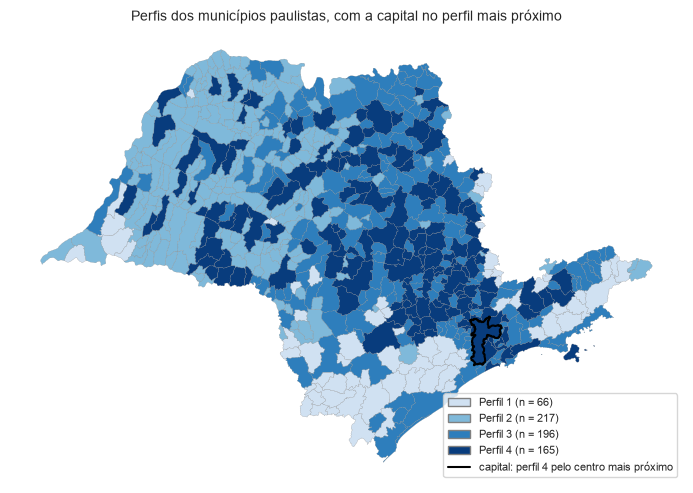

In [6]:
malha = carregar_malha_sp()
com_capital = pd.concat([perfis[["codigo_ibge", "perfil"]],
                         pd.DataFrame({"codigo_ibge": [CODIGO_CAPITAL],
                                       "perfil": [mais_proximo]})])
mapa = malha.merge(com_capital, on="codigo_ibge", how="left")
assert mapa["perfil"].notna().all(), "município sem perfil no mapa"

n_por_perfil = perfis["perfil"].value_counts().sort_index()
rotulos_mapa = {p: f"Perfil {p} (n = {n})" for p, n in n_por_perfil.items()}
fig = plot_mapa_com_destaque(
    mapa, "perfil", rotulos_mapa,
    "Perfis dos municípios paulistas, com a capital no perfil mais próximo",
    CODIGO_CAPITAL, f"capital: perfil {mais_proximo} pelo centro mais próximo")
salvar(fig, "figura_mapa_perfis_com_capital")

## 6. Saída

A `tabela_capital.csv` reúne, em formato de uma medida por linha, as
distâncias aos quatro perfis, o perfil mais próximo, o segundo mais próximo
e a taxa de acerto do teste da seção 3.

In [7]:
tabela = pd.DataFrame(
    [{"medida": f"distancia_perfil_{p}", "valor": d} for p, d in dist_capital.items()]
    + [{"medida": "perfil_mais_proximo", "valor": mais_proximo},
       {"medida": "perfil_segundo_mais_proximo", "valor": segundo},
       {"medida": "taxa_acerto_644", "valor": acerto},
       {"medida": "distancia_mediana_644_ao_centro_mais_proximo",
        "valor": dist_min_644.median()},
       {"medida": "pct_644_mais_longe_que_a_capital", "valor": 100 * mais_longe},
       {"medida": "variaveis_fora_da_faixa", "valor": int(variaveis["fora_da_faixa"].sum())}])
tabela.to_csv(DATA_PROCESSED / "tabela_capital.csv", index=False)
tabela.round(3)

,medida,valor
0,distancia_perfil_1,3.030
1,distancia_perfil_2,2.453
2,distancia_perfil_3,1.590
3,distancia_perfil_4,1.304
4,perfil_mais_proximo,4.000
5,perfil_segundo_mais_proximo,3.000
6,taxa_acerto_644,0.781
7,distancia_mediana_644_ao_centro_mais_proximo,0.986
8,pct_644_mais_longe_que_a_capital,23.447
9,variaveis_fora_da_faixa,1.000


## 7. Leitura

**Perfil mais próximo.** Nas 15 colunas de criminalidade e condição
socioeconômica, a capital fica mais próxima do centro do perfil 4
(distância de 1,304), seguido do perfil 3 (1,590); os perfis 2 (2,453) e 1
(3,030) ficam bem mais distantes. A distância ao perfil 4 é maior que a
distância mediana dos 644 municípios ao seu centro mais próximo (0,986), e
23,4% dos 644 ficam mais longe do seu centro do que a capital fica do perfil
4.

**Confiança do método.** Sem o bloco de gestão, a regra do centro mais
próximo devolve o perfil original de 503 dos 644 municípios (taxa de acerto
de 0,781). O acerto é alto nos perfis 1 (0,970) e 2 (0,899) e menor nos
perfis 3 (0,648) e 4 (0,709): 56 municípios do perfil 3 são apontados para o
perfil 4 e 37 do perfil 4 para o perfil 3. Como a capital fica entre esses
dois perfis, e eles se diferenciam sobretudo pelo bloco de gestão, ausente
para ela, a distinção entre o perfil 4 e o perfil 3 é justamente a parte
menos confiável do resultado.

**Extrapolação.** A capital fica fora da faixa dos 644 na taxa de roubo de
outros (952,88 por 100 mil hab./ano, contra máximo de 751,84). Nas demais
variáveis ela está dentro da faixa, mas bem acima da média de todos os
perfis nos crimes patrimoniais: furto de outros (2,80 desvios, contra 0,42
no perfil 4), roubo de outros (2,40, contra 0,52) e furto de veículo (2,06,
contra 0,60). Nas variáveis socioeconômicas, fica acima da média dos 644,
como o perfil 4, e nos crimes contra a pessoa fica perto ou abaixo dela
(CVLI 0,06; estupro −0,68).

Em síntese, a capital se aproxima mais do perfil 4, mas com a ressalva de que
a posição dela se apoia em uma extrapolação na taxa de roubo e em uma regra
que separa mal os perfis 3 e 4 sem as notas de gestão.